In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("retail_sales_2024.csv")

df["order_date"] = pd.to_datetime(df["order_date"])
df["month"] = df["order_date"].dt.month
df["quarter"] = df["order_date"].dt.quarter
df["profit_margin"] = df["profit"] / df["revenue"] * 100

print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())

df.head()

Shape: (1000, 18)
Missing values: 0


,order_id,order_date,region,category,product,quantity,unit_price,discount,revenue,profit,customer_age,customer_gender,payment_method,delivery_days,rating,month,quarter,profit_margin
0,ORD1001,2024-01-01,West,Clothing,Jeans,4,1730.0,0.00,6920.0,2636.14,45,Male,Debit Card,3,3.0,1,1,38.094509
1,ORD1002,2024-01-01,South,Sports,Dumbbell Set,1,2360.0,0.00,2360.0,690.43,39,Female,Credit Card,2,4.0,1,1,29.255508
2,ORD1003,2024-01-02,East,Clothing,T-Shirt,2,680.0,0.00,1360.0,456.07,31,Male,Credit Card,5,4.0,1,1,33.534559
3,ORD1004,2024-01-02,East,Clothing,Sneakers,3,2760.0,0.30,5796.0,887.30,24,Female,Credit Card,4,5.0,1,1,15.308834
4,ORD1005,2024-01-03,South,Clothing,Sneakers,2,2810.0,0.05,5339.0,1531.46,54,Female,UPI,2,3.0,1,1,28.684398


In [23]:
sns.set_theme(style="whitegrid", palette="Set2")

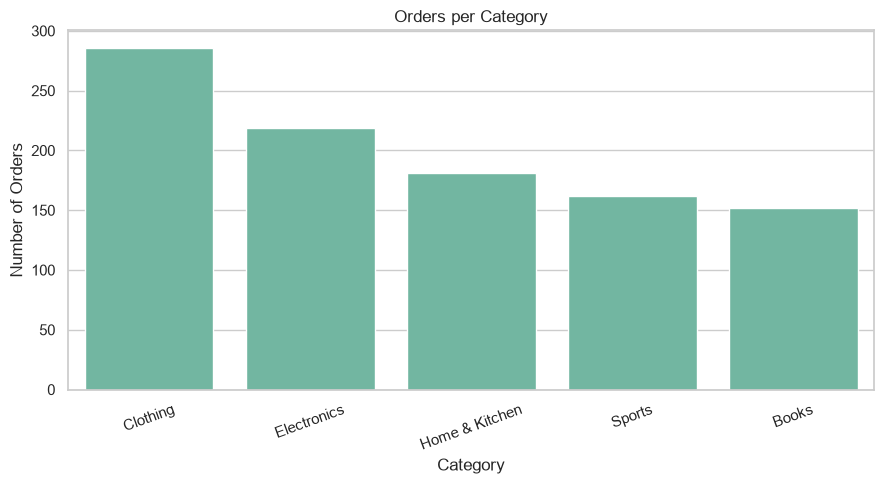

In [24]:
# 11

category_order = df["category"].value_counts().index

plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="category", order=category_order)
plt.title("Orders per Category")
plt.xlabel("Category")
plt.ylabel("Number of Orders")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

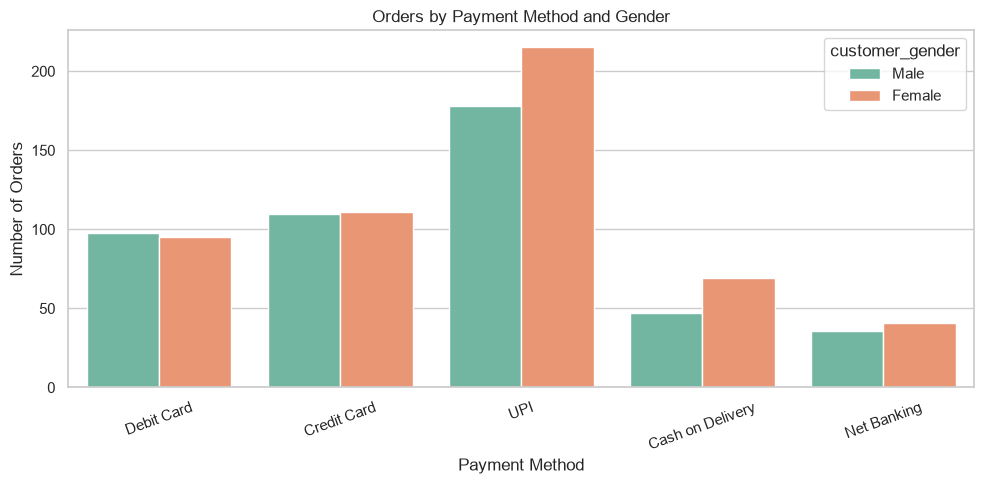

In [25]:
# 12

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="payment_method", hue="customer_gender")
plt.title("Orders by Payment Method and Gender")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

/var/folders/hw/l0hyxfmj56311bmm27fclk440000gn/T/ipykernel_8782/4157840155.py:9: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/adityaraj/Library/Python/3.14/lib/python/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


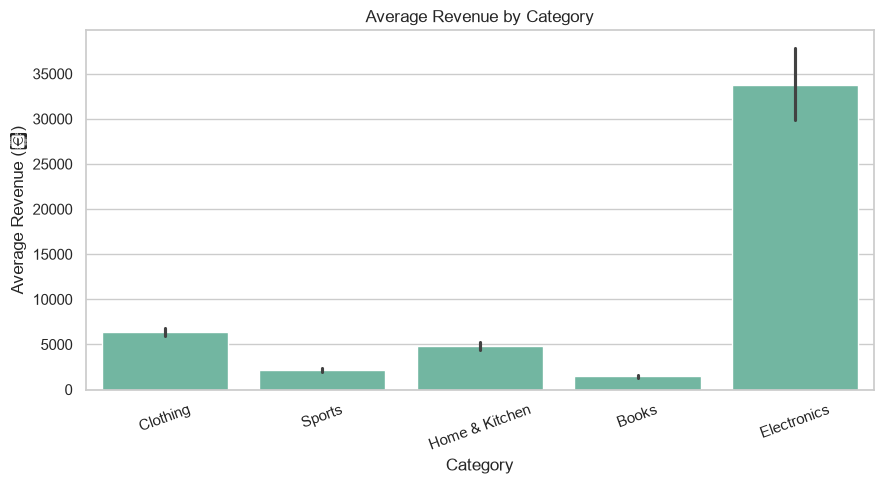

In [26]:
#13

plt.figure(figsize=(9, 5))
sns.barplot(data=df, x="category", y="revenue", errorbar="ci")
plt.title("Average Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Average Revenue (₹)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


/var/folders/hw/l0hyxfmj56311bmm27fclk440000gn/T/ipykernel_8782/2950176632.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=region_profit.values, y=region_profit.index, palette="viridis")
/var/folders/hw/l0hyxfmj56311bmm27fclk440000gn/T/ipykernel_8782/2950176632.py:10: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/adityaraj/Library/Python/3.14/lib/python/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


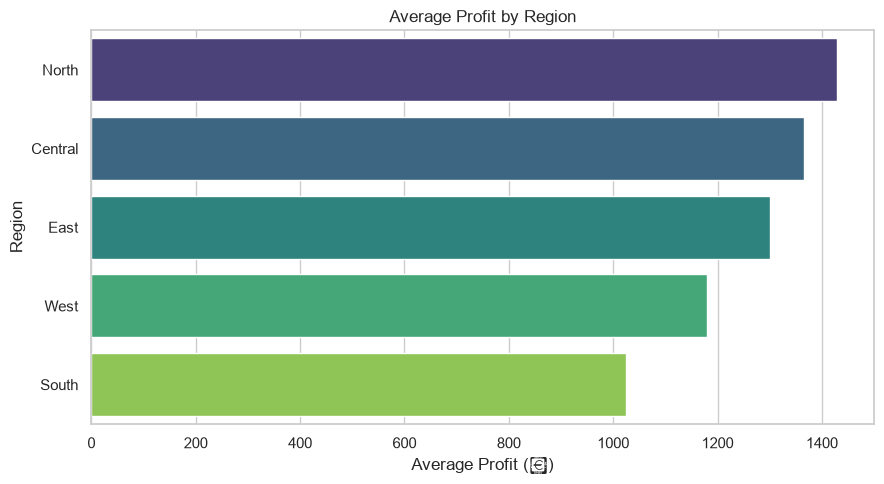

In [27]:
# 14

region_profit = df.groupby("region")["profit"].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=region_profit.values, y=region_profit.index, palette="viridis")
plt.title("Average Profit by Region")
plt.xlabel("Average Profit (₹)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

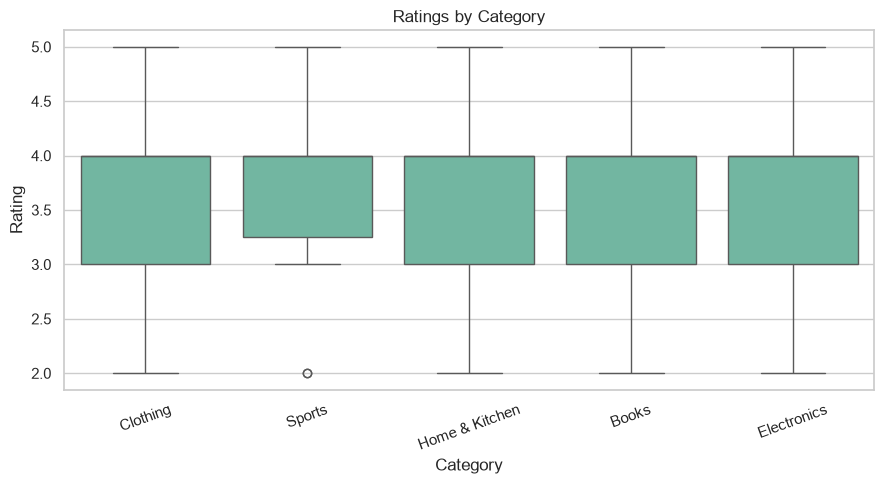

Median rating by category:
category
Books             4.0
Clothing          4.0
Electronics       4.0
Home & Kitchen    4.0
Sports            4.0
Name: rating, dtype: float64
Category with highest median rating: Books


In [28]:
# 15

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="category", y="rating")
plt.title("Ratings by Category")
plt.xlabel("Category")
plt.ylabel("Rating")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

median_ratings = df.groupby("category")["rating"].median().sort_values(ascending=False)
print("Median rating by category:")
print(median_ratings)
print("Category with highest median rating:", median_ratings.index[0])

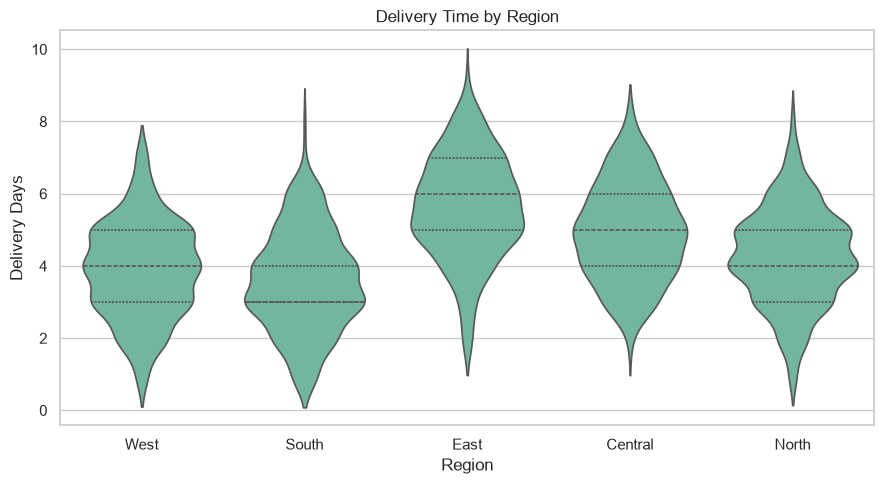

Average delivery days by region:
region
East       5.620253
Central    4.944954
North      4.261818
West       3.887850
South      3.577869
Name: delivery_days, dtype: float64
Region with the highest average delivery time: East


In [29]:
# 16

plt.figure(figsize=(9, 5))
sns.violinplot(data=df, x="region", y="delivery_days", inner="quartile")
plt.title("Delivery Time by Region")
plt.xlabel("Region")
plt.ylabel("Delivery Days")
plt.tight_layout()
plt.show()

mean_delivery = df.groupby("region")["delivery_days"].mean().sort_values(ascending=False)
print("Average delivery days by region:")
print(mean_delivery)
print("Region with the highest average delivery time:", mean_delivery.index[0])

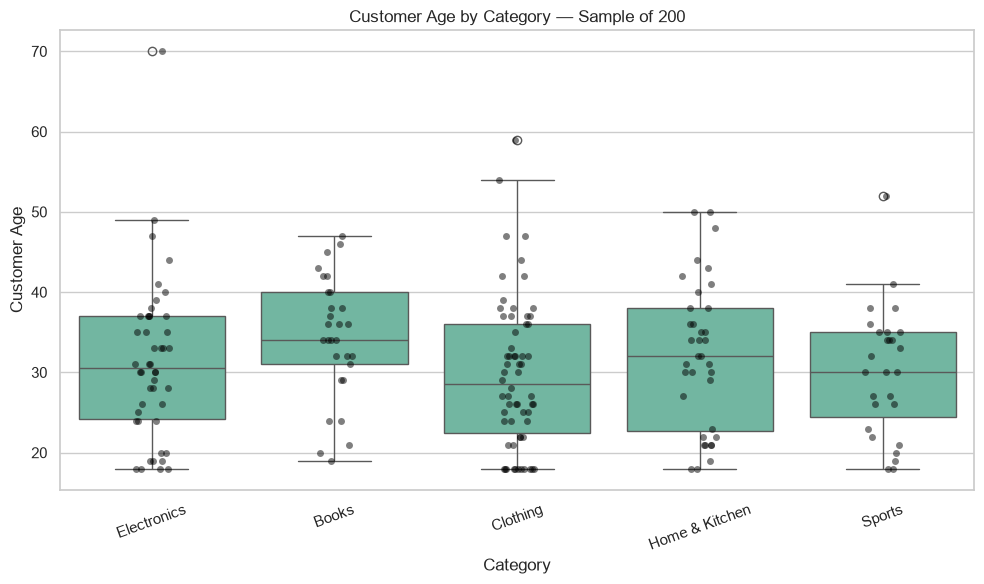

In [30]:
# 17

sample = df.sample(200, random_state=1)

plt.figure(figsize=(10, 6))
sns.boxplot(data=sample, x="category", y="customer_age")
sns.stripplot(data=sample, x="category", y="customer_age",
              color="black", alpha=0.5, jitter=True)

plt.title("Customer Age by Category — Sample of 200")
plt.xlabel("Category")
plt.ylabel("Customer Age")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

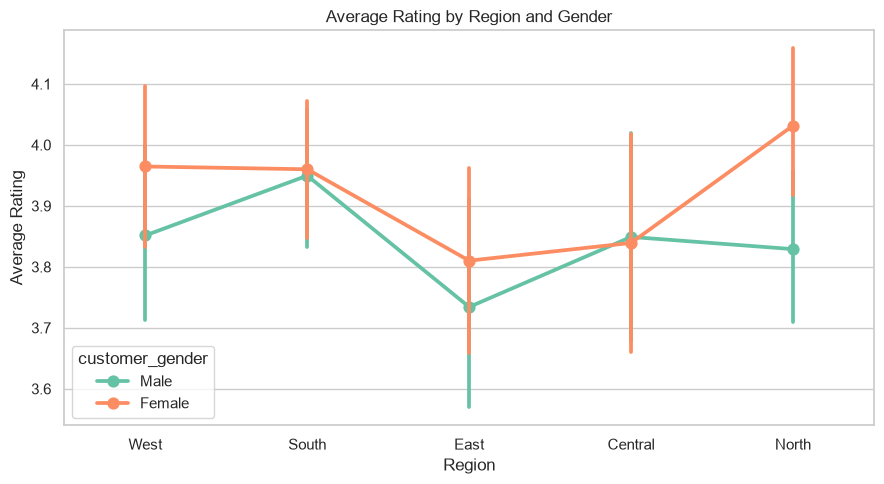

In [31]:
# 18

plt.figure(figsize=(9, 5))
sns.pointplot(data=df, x="region", y="rating", hue="customer_gender")
plt.title("Average Rating by Region and Gender")
plt.xlabel("Region")
plt.ylabel("Average Rating")
plt.tight_layout()
plt.show()

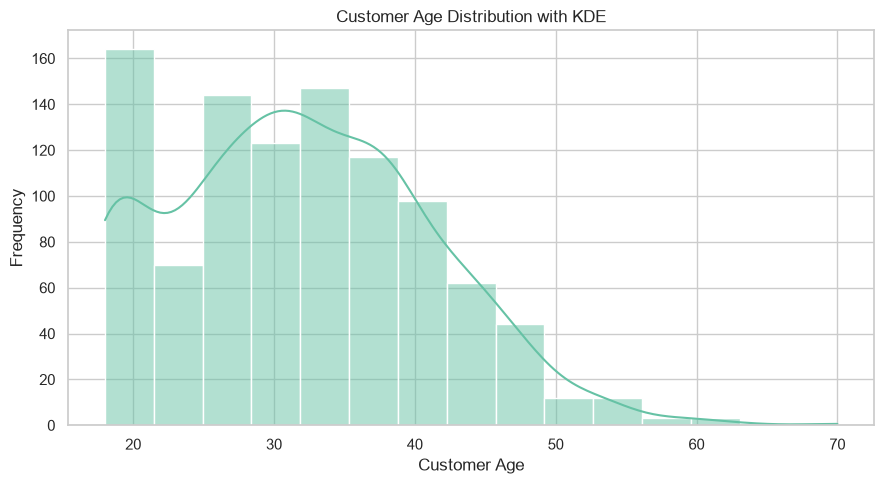

In [32]:
# 19

plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="customer_age", bins=15, kde=True)
plt.title("Customer Age Distribution with KDE")
plt.xlabel("Customer Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

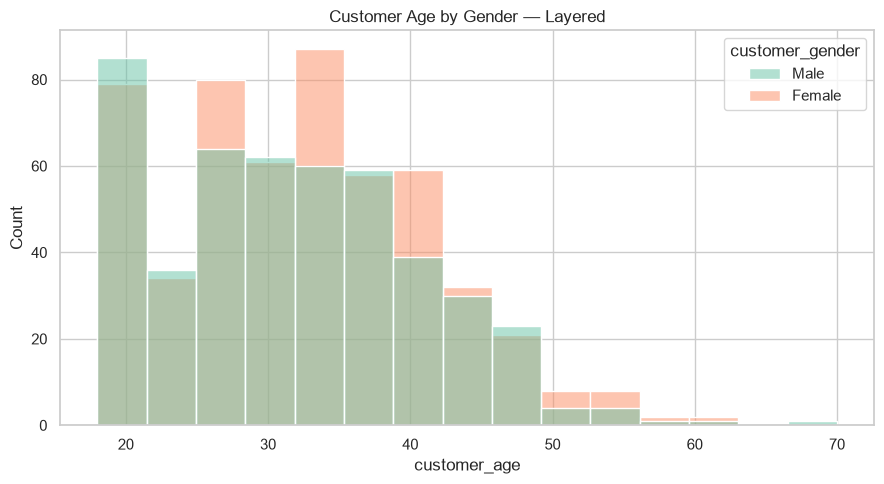

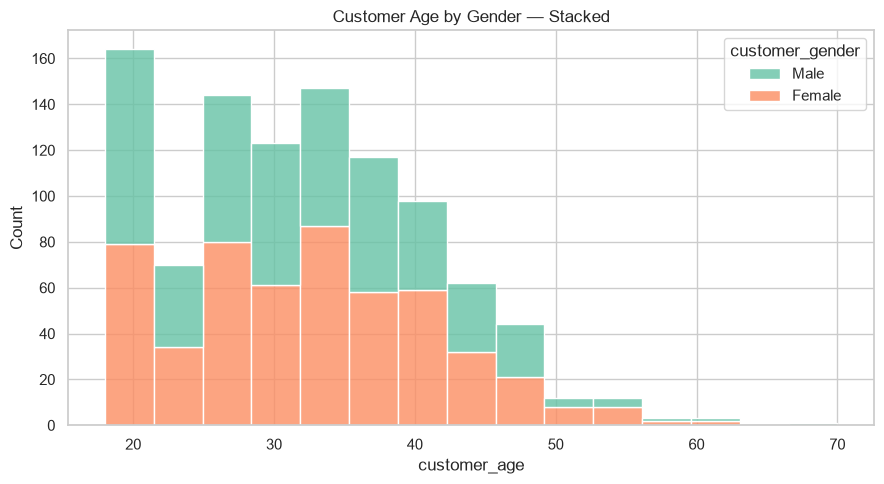

In [33]:
# 20
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="customer_age", hue="customer_gender",
             bins=15, multiple="layer", alpha=0.5)
plt.title("Customer Age by Gender — Layered")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="customer_age", hue="customer_gender",
             bins=15, multiple="stack", alpha=0.8)
plt.title("Customer Age by Gender — Stacked")
plt.tight_layout()
plt.show()

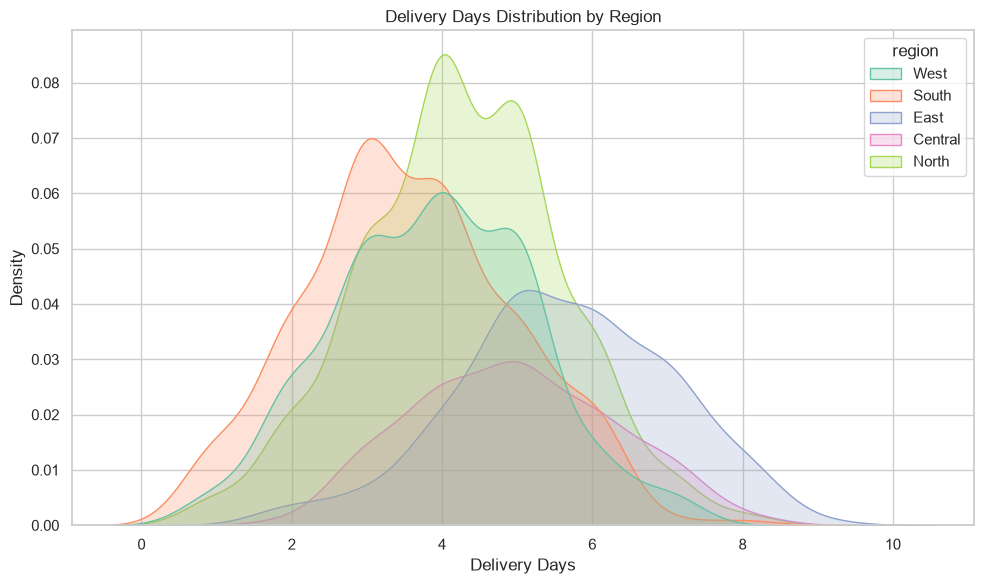

             mean       std
region                     
Central  4.944954  1.311169
East     5.620253  1.407928
North    4.261818  1.311306
South    3.577869  1.375148
West     3.887850  1.309604
Two regions with the most similar mean delivery times: South and West


In [34]:
# 21

plt.figure(figsize=(10, 6))
sns.kdeplot(data=df, x="delivery_days", hue="region", fill=True)
plt.title("Delivery Days Distribution by Region")
plt.xlabel("Delivery Days")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

delivery_stats = df.groupby("region")["delivery_days"].agg(["mean", "std"])
print(delivery_stats)

pairs = []
regions = delivery_stats.index.tolist()

for i in range(len(regions)):
    for j in range(i + 1, len(regions)):
        r1, r2 = regions[i], regions[j]
        difference = abs(delivery_stats.loc[r1, "mean"] -
                         delivery_stats.loc[r2, "mean"])
        pairs.append((difference, r1, r2))

pairs.sort()
print("Two regions with the most similar mean delivery times:",
      pairs[0][1], "and", pairs[0][2])

/var/folders/hw/l0hyxfmj56311bmm27fclk440000gn/T/ipykernel_8782/3541525546.py:9: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/adityaraj/Library/Python/3.14/lib/python/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


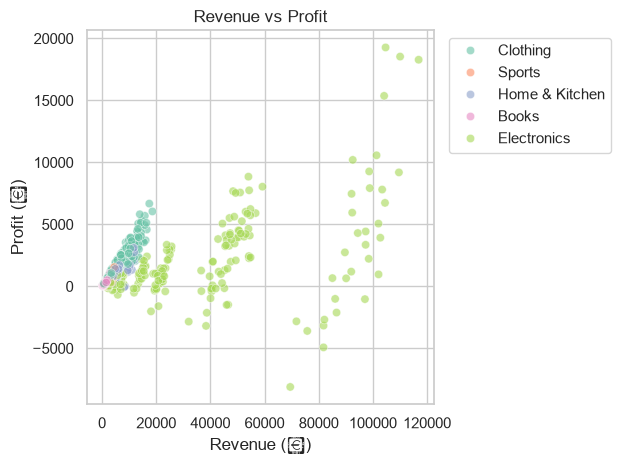

In [35]:
# 22

g = sns.scatterplot(data=df, x="revenue", y="profit",
                     hue="category", alpha=0.6)
g.set_title("Revenue vs Profit")
g.set_xlabel("Revenue (₹)")
g.set_ylabel("Profit (₹)")
g.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

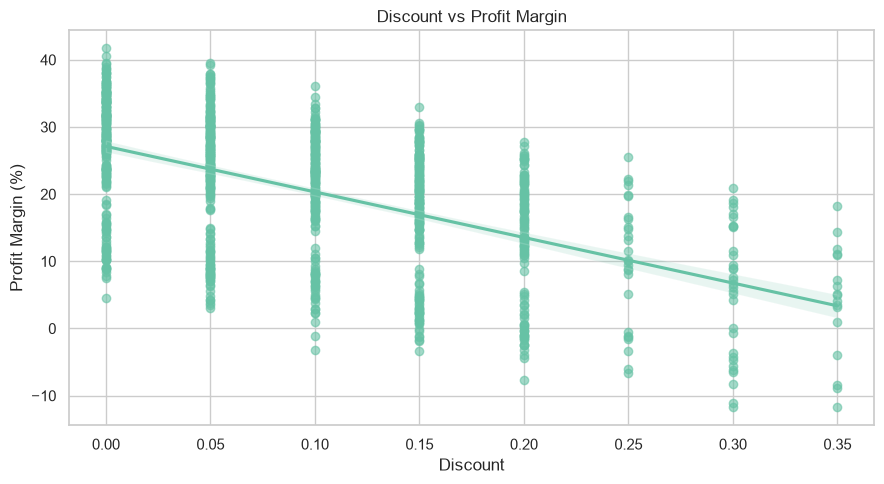

Correlation between discount and profit margin: -0.5481495219075035
Relationship: negative


In [36]:
# 23

plt.figure(figsize=(9, 5))
sns.regplot(data=df, x="discount", y="profit_margin",
            scatter_kws={"alpha": 0.6})
plt.title("Discount vs Profit Margin")
plt.xlabel("Discount")
plt.ylabel("Profit Margin (%)")
plt.tight_layout()
plt.show()

corr = df["discount"].corr(df["profit_margin"])
print("Correlation between discount and profit margin:", corr)

if corr > 0.1:
    print("Relationship: positive")
elif corr < -0.1:
    print("Relationship: negative")
else:
    print("Relationship: approximately none/very weak")

/var/folders/hw/l0hyxfmj56311bmm27fclk440000gn/T/ipykernel_8782/3629469002.py:15: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/adityaraj/Library/Python/3.14/lib/python/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


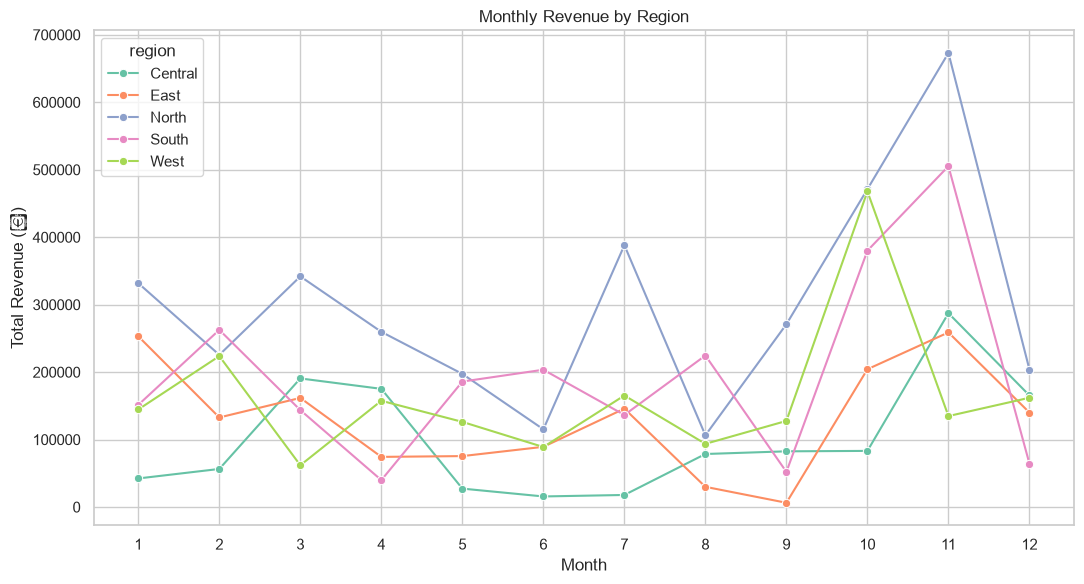

In [37]:
# 24

monthly_region = (
    df.groupby(["month", "region"], as_index=False)["revenue"].sum()
)

plt.figure(figsize=(11, 6))
sns.lineplot(data=monthly_region,
             x="month", y="revenue", hue="region",
             marker="o", errorbar=None)
plt.xticks(range(1, 13))
plt.title("Monthly Revenue by Region")
plt.xlabel("Month")
plt.ylabel("Total Revenue (₹)")
plt.tight_layout()
plt.show()

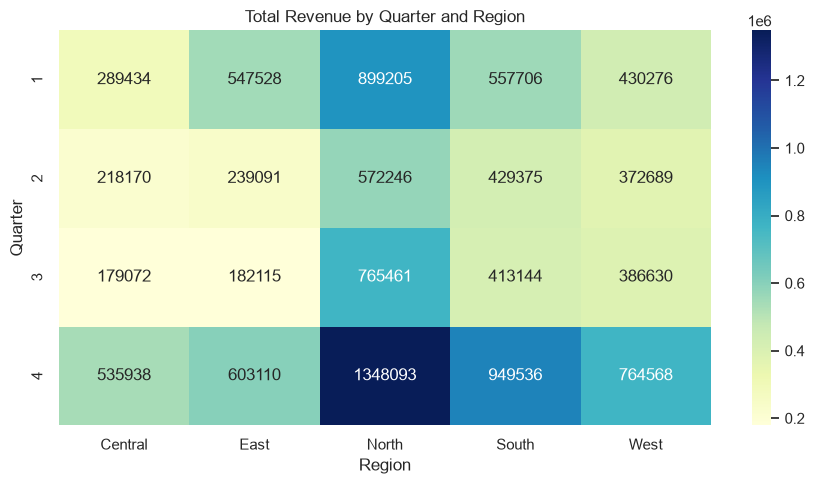

In [38]:
# 26

revenue_pivot = df.pivot_table(
    values="revenue",
    index="quarter",
    columns="region",
    aggfunc="sum"
)

plt.figure(figsize=(9, 5))
sns.heatmap(revenue_pivot, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Total Revenue by Quarter and Region")
plt.xlabel("Region")
plt.ylabel("Quarter")
plt.tight_layout()
plt.show()

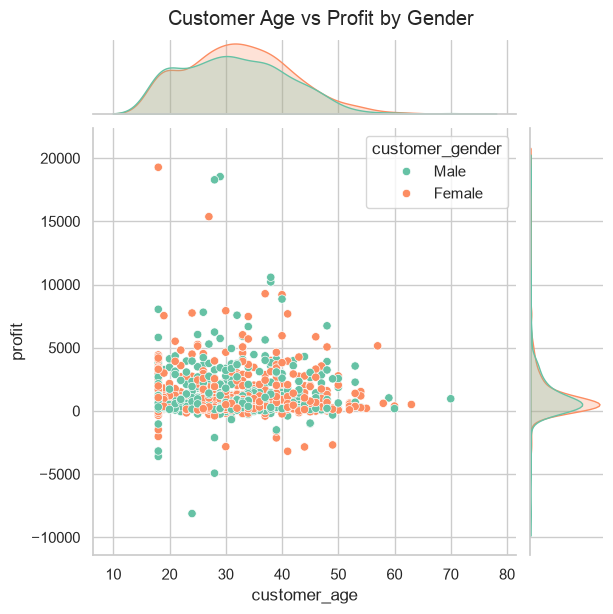

In [39]:
# 27

g = sns.jointplot(
    data=df,
    x="customer_age",
    y="profit",
    hue="customer_gender"
)
g.fig.suptitle("Customer Age vs Profit by Gender", y=1.02)
plt.show()

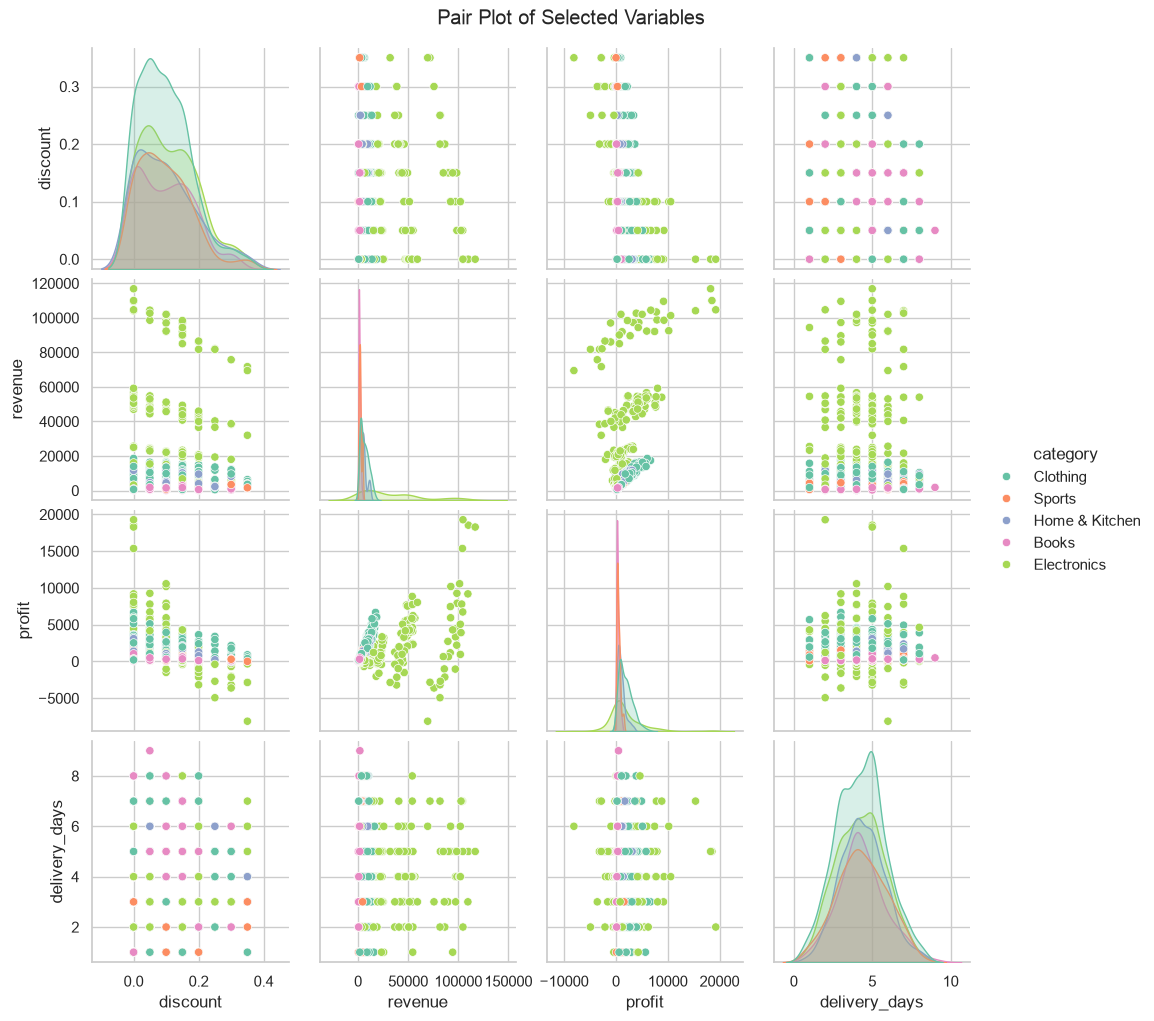

               discount   revenue    profit  delivery_days
discount       1.000000  0.016076 -0.311173      -0.042822
revenue        0.016076  1.000000  0.535362       0.004231
profit        -0.311173  0.535362  1.000000      -0.008749
delivery_days -0.042822  0.004231 -0.008749       1.000000


In [40]:
# 28

pair_data = df[["discount", "revenue", "profit",
                       "delivery_days", "category"]]

g = sns.pairplot(pair_data, hue="category", diag_kind="kde")
g.fig.suptitle("Pair Plot of Selected Variables", y=1.02)
plt.show()
print(df[["discount", "revenue", "profit", "delivery_days"]].corr())

/Users/adityaraj/Library/Python/3.14/lib/python/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


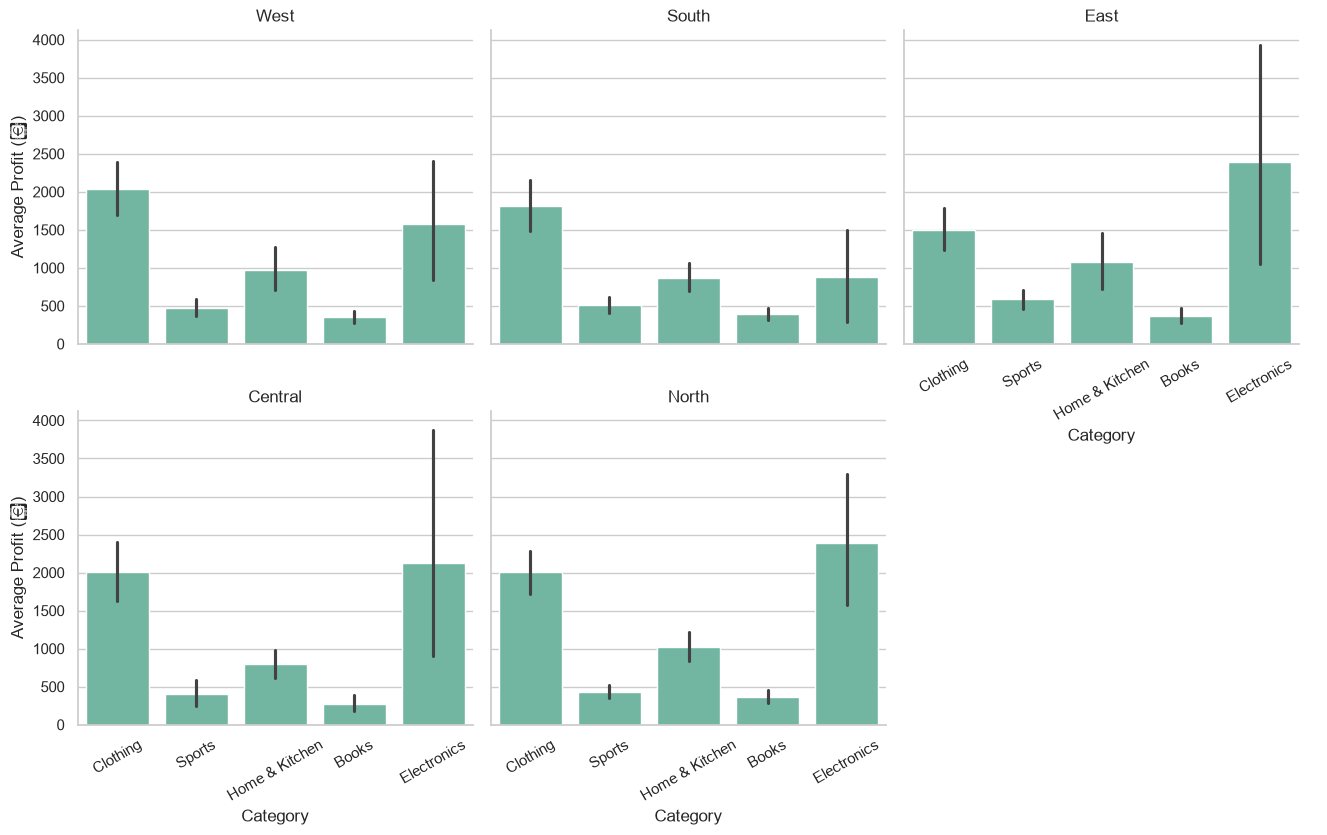

In [41]:
# 29

g = sns.catplot(
    data=df,
    kind="bar",
    x="category",
    y="profit",
    col="region",
    col_wrap=3,
    height=4,
    aspect=1.1
)

g.set_axis_labels("Category", "Average Profit (₹)")
g.set_titles("{col_name}")
for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=30)

plt.show()

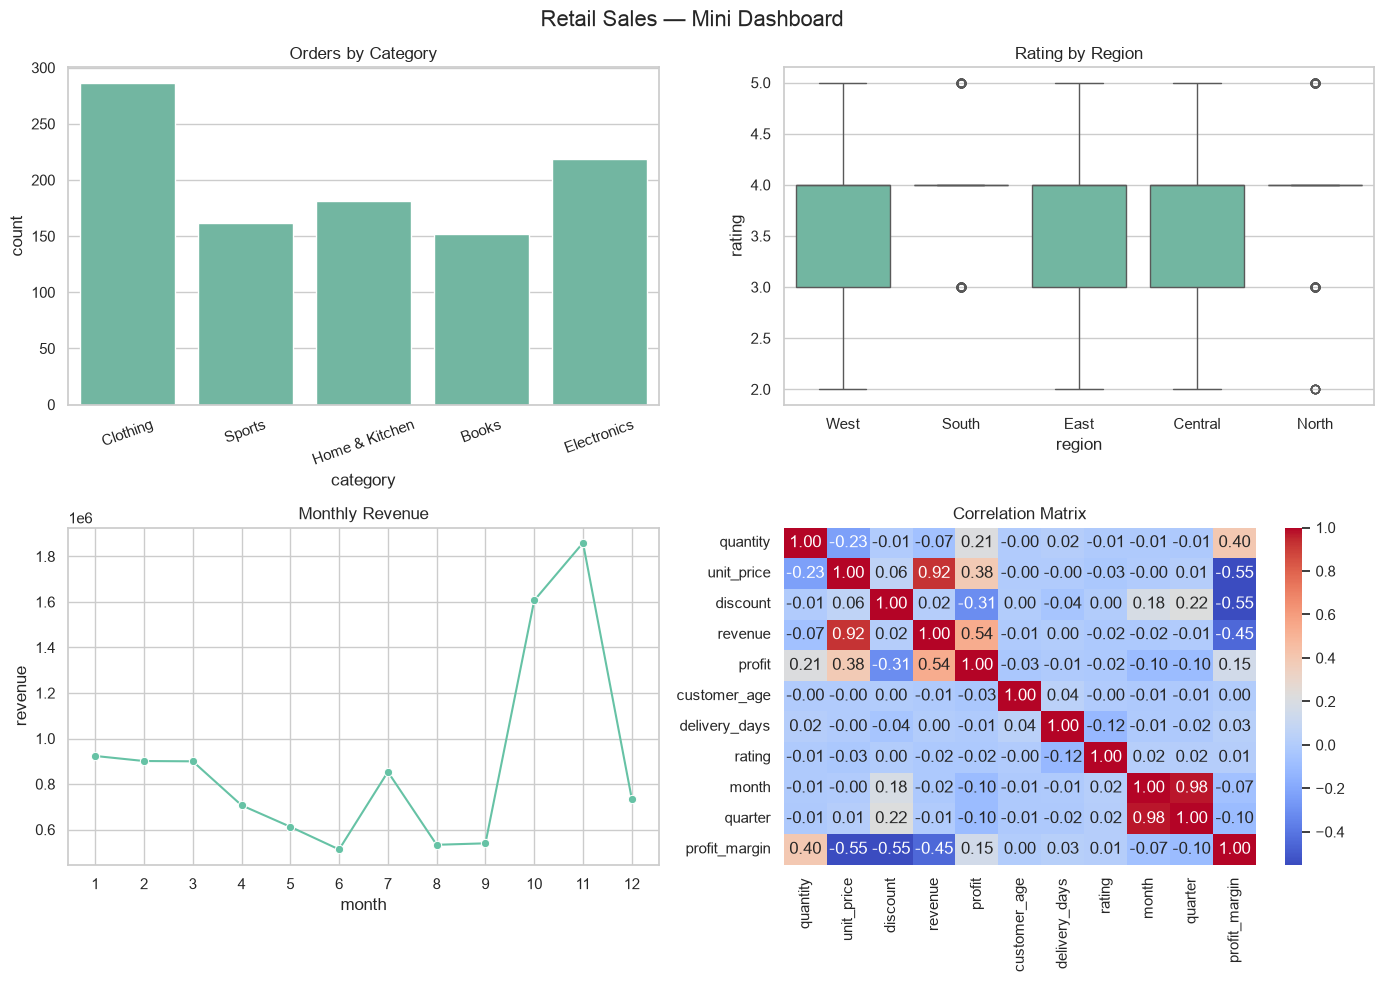

In [42]:
# 30

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.countplot(data=df, x="category", ax=axes[0, 0])
axes[0, 0].set_title("Orders by Category")
axes[0, 0].tick_params(axis="x", rotation=20)

sns.boxplot(data=df, x="region", y="rating", ax=axes[0, 1])
axes[0, 1].set_title("Rating by Region")


monthly_revenue_df = df.groupby("month", as_index=False)["revenue"].sum()
sns.lineplot(data=monthly_revenue_df, x="month", y="revenue",
             marker="o", ax=axes[1, 0])
axes[1, 0].set_title("Monthly Revenue")
axes[1, 0].set_xticks(range(1, 13))

corr = df.select_dtypes("number").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1, 1])
axes[1, 1].set_title("Correlation Matrix")

fig.suptitle("Retail Sales — Mini Dashboard", fontsize=16)
plt.tight_layout()
plt.savefig("dashboard.png", dpi=300, bbox_inches="tight")
plt.show()